# 01. The chat handoff simulator

A chat runs for up to 40 turns. At each turn the confounders update, a handoff
may happen, a complaint may happen and the chat may end. Handoffs feed back into
later confounders: a transfer adds queue time at the next turn, raises
frustration and resets resolution progress. Frustration then drives later
escalations and complaints. That feedback is time-varying confounding affected
by earlier treatment.

The simulator knows the true effect of every intervention, because it can rerun
the same chats with handoffs switched off.

In [1]:
import numpy as np
import pandas as pd

from gmethods import ChatSimulator, Scenario
from gmethods import interventions as iv

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

## Scenario and data

Every knob lives on `Scenario`. Presets switch sources of bias on and off:
`baseline`, `null`, `strong_feedback`, `noisy_sentiment`,
`unmeasured_confounding` and `poor_positivity`.

In [3]:
sim = ChatSimulator(Scenario.preset("baseline"))
data = sim.simulate(n_chats=20_000, seed=0)
chats = data.chats
print(f"chats: {len(chats):,}  chat-turns: {len(data.panel):,}")
print(f"complaint rate: {chats['complained'].mean():.2%}")
print(f"mean turns: {chats['n_turns'].mean():.1f}")
chats[[f"n_{k}" for k in ["transfer", "escalation", "requeue", "shift_change"]]].mean().round(3)

chats: 20,000  chat-turns: 134,588
complaint rate: 2.05%
mean turns: 6.7


n_transfer        0.219
n_escalation      0.133
n_requeue         0.082
n_shift_change    0.092
dtype: float64

## Three views of the same data

- `panel`: one row per chat-turn while the chat is open and before any complaint.
  This is what the g-methods use.
- `event_log`: timestamped events, as a support platform logs them. It includes
  escalations logged *after* a complaint, the reverse-causality artefact.
- `chats`: one row per chat with counts. This is what a naive analysis uses.

In [4]:
one = chats.loc[(chats["complained"] == 1) & (chats["total_agents"] >= 3), "chat_id"].iloc[0]
cols = ["turn", "queue_length", "wait", "sentiment", "idle", "skill_mismatch",
        "with_specialist", "handoff", "complaint", "ended"]
data.panel.loc[data.panel["chat_id"] == one, cols].round(2)

,turn,queue_length,wait,sentiment,idle,skill_mismatch,with_specialist,handoff,complaint,ended
380,1,8.38,0.56,0.60,2.70,1,0,none,0,0
381,2,6.93,0.60,0.99,1.45,1,0,none,0,0
382,3,5.77,0.60,1.38,0.33,1,0,none,0,0
383,4,9.27,0.91,1.77,0.75,1,0,none,0,0
384,5,8.62,1.56,2.17,4.22,1,0,none,0,0
385,6,7.92,0.30,3.13,4.45,1,0,none,0,0
386,7,8.33,0.86,2.35,11.98,1,0,none,0,0
387,8,9.98,2.05,2.80,2.34,1,0,transfer,0,0
388,9,10.67,4.40,4.32,0.01,0,0,none,0,0
389,10,10.46,1.55,4.73,6.81,0,0,requeue,0,0


In [5]:
data.event_log[data.event_log["chat_id"] == one]

,chat_id,customer_id,event,handoff_type,turn,timestamp
518,53,42,chat_start,NaN,0,2026-01-08 01:07:00.000000000
519,53,42,agent_reply,NaN,1,2026-01-08 01:10:04.255923431
520,53,42,agent_reply,NaN,2,2026-01-08 01:15:09.966853722
521,53,42,agent_reply,NaN,3,2026-01-08 01:18:30.464812349
522,53,42,agent_reply,NaN,4,2026-01-08 01:21:03.586474374
523,53,42,agent_reply,NaN,5,2026-01-08 01:23:42.990812724
524,53,42,agent_reply,NaN,6,2026-01-08 01:29:22.756085700
525,53,42,agent_reply,NaN,7,2026-01-08 01:38:10.537394400
526,53,42,agent_reply,NaN,8,2026-01-08 01:56:00.402447618
527,53,42,handoff,transfer,8,2026-01-08 01:58:20.835825078


Read the wait column against the handoff column one row up. Wait at turn t is
the wait *going into* turn t, so it carries the queue time caused by the handoff
at turn t-1. It can confound the handoff at turn t but is never caused by it.

## The truth

`true_risks` reruns the structural equations under each intervention. Every
regime sees the same chats and random numbers, so the differences between
regimes carry little Monte Carlo noise. "Never k" means a draw of k becomes no
handoff: the same agent carries on, and whatever triggered the handoff is still
there.

In [6]:
regimes = [*iv.standard_set(), iv.scale("escalation", factor=0.5)]
truth = sim.true_risks(regimes, n_mc=200_000)
truth.to_frame().round(4)

,risk,rd,rr,avoided_per_1000
regime,,,,
natural_course,0.0211,0.0000,1.0000,0.0000
never_transfer,0.0206,-0.0005,0.9772,0.4816
never_escalation,0.0170,-0.0041,0.8053,4.1069
never_requeue,0.0180,-0.0031,0.8534,3.0922
never_shift_change,0.0198,-0.0013,0.9375,1.3176
never_any,0.0154,-0.0057,0.7292,5.7137
scale_escalation_0.5,0.0192,-0.0019,0.9100,1.8990


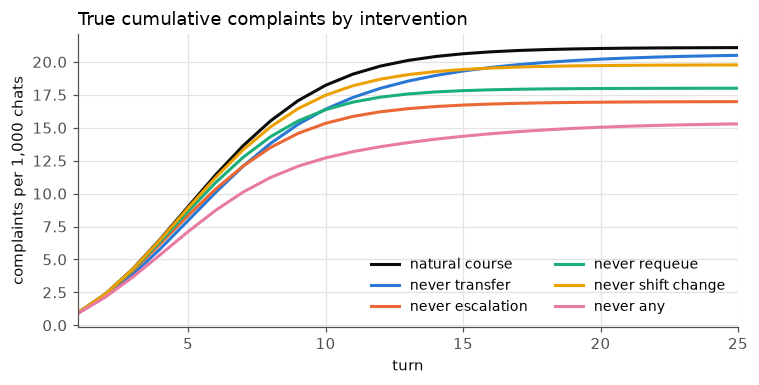

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
show = ["natural_course", "never_transfer", "never_escalation", "never_requeue",
        "never_shift_change", "never_any"]
for i, name in enumerate(show):
    curve = truth.curves[name] * 1000
    ax.plot(np.arange(1, len(curve) + 1), curve, lw=2, color=INK if i == 0 else SERIES[i - 1],
            label=name.replace("_", " "))
ax.set_xlim(1, 25)
ax.set_xlabel("turn")
ax.set_ylabel("complaints per 1,000 chats")
ax.set_title("True cumulative complaints by intervention", loc="left")
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()

The single-type effects sum to more than "never any". Each one includes
complaints that also run through other handoffs (a transfer that raises
frustration and so triggers a later escalation), so summing them counts the
shared routes twice.

In [8]:
f = truth.to_frame()
parts = f.loc[["never_transfer", "never_escalation", "never_requeue", "never_shift_change"], "rd"]
print(f"sum of single-type RDs: {parts.sum():.4f}")
print(f"never_any RD:          {f.loc['never_any', 'rd']:.4f}")

sum of single-type RDs: -0.0090
never_any RD:          -0.0057


## Null check

With every handoff effect set to zero, every true risk difference is zero.

In [9]:
null = ChatSimulator(Scenario.preset("null")).true_risks(iv.standard_set(), n_mc=50_000)
null.to_frame()["rd"].round(6)

regime
natural_course        0.0
never_transfer        0.0
never_escalation      0.0
never_requeue         0.0
never_shift_change    0.0
never_any             0.0
Name: rd, dtype: float64